<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Practical_Final_Exam_of_stats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practical Final exam

PROBLEM STATEMENT:

**K3: PageRank for a small website**

A university website's SEO team wants to know which of its six pages a random visitor lands on most often.

Link structure:
- Home -> About, Courses, Blog
- About -> Home
- Courses -> Home, Apply, Blog
- Blog -> Courses, About
- Apply -> Fees, Courses
- Fees -> Home

TASKS:
1. Build the 6x6 column-stochastic (or row-stochastic, keep convention consistent with G = d*P + (1-d)/6) transition matrix P where a visitor picks one outgoing link uniformly at random. Print P.
2. Build the Google matrix G = d * P + (1 - d) / 6 with damping factor d = 0.85. Print G.
3. Compute PageRank by power iteration until the L1 norm change between iterations is below 1e-8. Print the exact number of iterations and the ranked pages with their PageRank scores.
4. Verify the answer using networkx.pagerank (with alpha=0.85 and tol=1e-8) and print the scores side-by-side for comparison.
5. Repeat the PageRank calculation with d = 0.5, print the new scores, and plot a grouped bar chart comparing the PageRank rankings/scores for d = 0.85 and d = 0.5.

# **Step 1. Importing Libraries**

numpy: Creates and performs calculations on matrices.



pandas: Displays matrices and results in table format.



networkx: Verifies PageRank.



matplotlib: Creates the bar chart.

In [4]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt



# **Step 2. Define Pages and Links**

pages stores all six website pages.



n counts the total pages (6).



idx assigns an index to every page, from 0 to 5.

First, we define six website pages and assign an index to each page.

In [5]:
pages = ['Home', 'About', 'Courses', 'Blog', 'Apply', 'Fees']
n = len(pages)
idx = {page: i for i, page in enumerate(pages)}

This dictionary stores which pages are connected to each other.

It represents the website's link structure, showing where a visitor can go from each page.

In [6]:
links = {
    'Home': ['About', 'Courses', 'Blog'],
    'About': ['Home'],
    'Courses': ['Home', 'Apply', 'Blog'],
    'Blog': ['Courses', 'About'],
    'Apply': ['Fees', 'Courses'],
    'Fees': ['Home']
}

#**Step 3. Create Transition Matrix (P)**

np.zeros() creates a 6×6 matrix filled with zeros.



The loops check every outgoing link.



Each link gets an equal probability.



1.0 / len(dests) calculates the probability of choosing a link.



P[idx[dst], idx[src]] stores that probability in the matrix.

We create a 6×6 transition matrix. Each outgoing link gets an equal probability. It is column-stochastic, meaning every column adds up to 1.

In [8]:
P = np.zeros((n, n))

for src, dests in links.items():
    for dst in dests:
        P[idx[dst], idx[src]] = 1.0 / len(dests)

This prints the transition matrix with page names as row and column labels.

In [9]:
print(pd.DataFrame(P, index=pages, columns=pages).round(4))

           Home  About  Courses  Blog  Apply  Fees
Home     0.0000    1.0   0.3333   0.0    0.0   1.0
About    0.3333    0.0   0.0000   0.5    0.0   0.0
Courses  0.3333    0.0   0.0000   0.5    0.5   0.0
Blog     0.3333    0.0   0.3333   0.0    0.0   0.0
Apply    0.0000    0.0   0.3333   0.0    0.0   0.0
Fees     0.0000    0.0   0.0000   0.0    0.5   0.0


#**Step 4. Create Google Matrix (G)**

d1 = 0.85 sets the damping factor.



0.85 represents following existing links.



0.15 represents randomly jumping to another page.



G1 creates the Google matrix.

Farmula : G = d*P + [ (1 - d)/6]


The Google matrix combines normal link-following probability with random jumping probability.

In [10]:
d1 = 0.85
G1 = d1 * P + (1 - d1) / n

This displays the Google matrix.

In [11]:
print(pd.DataFrame(G1, index=pages, columns=pages).round(4))

           Home  About  Courses   Blog  Apply   Fees
Home     0.0250  0.875   0.3083  0.025  0.025  0.875
About    0.3083  0.025   0.0250  0.450  0.025  0.025
Courses  0.3083  0.025   0.0250  0.450  0.450  0.025
Blog     0.3083  0.025   0.3083  0.025  0.025  0.025
Apply    0.0250  0.025   0.3083  0.025  0.025  0.025
Fees     0.0250  0.025   0.0250  0.025  0.450  0.025


#**Step 5. Power Iteration Function**

Defines a function to calculate PageRank.



r gives every page an equal initial score.



iterations counts how many times we update the scores.



tol is the stopping limit (10⁻⁸).

We start by assigning equal PageRank scores to all six pages.

G @ r multiplies the Google matrix with the current PageRank scores.



It calculates the new scores.



iterations increases by one.

We repeatedly multiply the Google matrix by the PageRank vector to calculate updated scores.

Calculates the difference between old and new scores.



np.linalg.norm(..., 1) calculates the L1 difference.



If the difference becomes smaller than 1e-8, the loop stops.



Returns final scores and iteration count.

Iteration continues until the PageRank scores become almost stable.

In [17]:
def power_iteration(G, tol=1e-8):
    r = np.ones(n) / n
    iterations = 0
    while True:
        r_next = G @ r
        iterations += 1
        if np.linalg.norm(r_next - r, 1) < tol:
            break
        r = r_next
    return r_next, iterations

#**Step 6. Calculate PageRank (d = 0.85)**

Calls the function and calculates PageRank using damping factor 0.85.

In [21]:
pr_85, iter_85 = power_iteration(G1, tol=1e-8)

Creates a table of pages and their scores.



sort_values() arranges scores from highest to lowest.



reset_index() resets the table numbering.

We arrange all pages according to their PageRank scores, from highest to lowest.

In [22]:
rank_df_85 = pd.DataFrame({
    'Page': pages,
    'PageRank (d=0.85)': pr_85
}).sort_values(
    by='PageRank (d=0.85)', ascending=False
).reset_index(drop=True)

#**Step 7. Verify Using NetworkX**

nx.DiGraph() creates a directed graph.



add_edge() connects pages according to their links.

We create a directed website graph using NetworkX.

In [23]:
graph = nx.DiGraph()

for src, dests in links.items():
    for dst in dests:
        graph.add_edge(src, dst)

NetworkX calculates PageRank independently using its built-in function.

We verify our manually calculated PageRank using NetworkX.

In [24]:
nx_pr = nx.pagerank(graph, alpha=0.85, tol=1e-8)

This creates a comparison table showing our results beside NetworkX results.

In [25]:
comp_df = pd.DataFrame({
    'Page': pages,
    'Power Iteration (d=0.85)': pr_85,
    'NetworkX PageRank': [nx_pr[p] for p in pages]
}).sort_values(
    by='Power Iteration (d=0.85)', ascending=False
).reset_index(drop=True)

#**Step 8. Calculate PageRank with d = 0.5**

Changes the damping factor from 0.85 to 0.5.



Creates a new Google matrix.



Calculates new PageRank scores.

We repeat PageRank calculation with a 0.5 damping factor to observe how the scores change.

In [26]:
d2 = 0.5
G2 = d2 * P + (1 - d2) / n

pr_50, iter_50 = power_iteration(G2, tol=1e-8)

#**Step 9. Compare Both Results**

Creates a comparison table.



Shows scores for both damping factors.



Calculates the difference between the scores.

We compare both PageRank scores and check which pages gained or lost importance.

In [27]:
summary_df = pd.DataFrame({
    'Page': pages,
    'd=0.85': pr_85,
    'd=0.50': pr_50,
    'Difference (d=0.50 - d=0.85)': pr_50 - pr_85
}).sort_values(by='d=0.85', ascending=False).reset_index(drop=True)

#**Step 10. Plot Grouped Bar Chart**

Creates positions for six pages and sets the width of the bars


In [28]:
x = np.arange(len(summary_df['Page']))
width = 0.35

Creates the chart.



First bar represents d = 0.85.



Second bar represents d = 0.50.

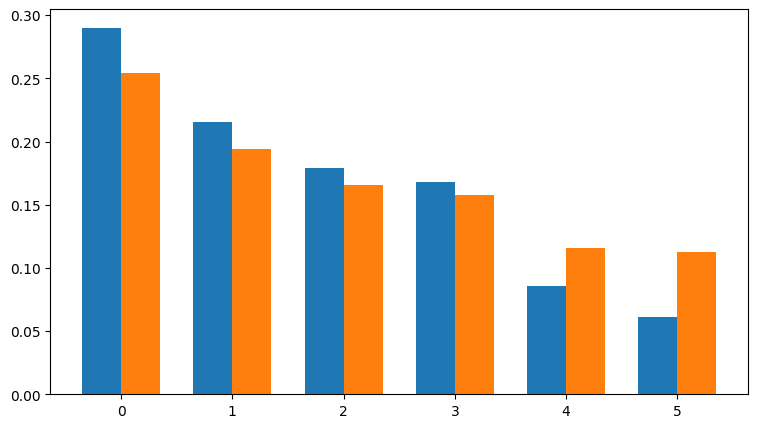

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, summary_df['d=0.85'], width, label='d = 0.85')
bars2 = ax.bar(x + width/2, summary_df['d=0.50'], width, label='d = 0.50')

Adds the chart title.



Labels X-axis and Y-axis.



Displays page names.



Adds a legend and grid.



plt.show() displays the final chart.

Finally, we create a grouped bar chart to visually compare PageRank scores for both damping factors.

In [31]:
ax.set_title('PageRank Score Comparison: d = 0.85 vs d = 0.50')
ax.set_xlabel('Website Pages')
ax.set_ylabel('PageRank Score')
ax.set_xticks(x)
ax.set_xticklabels(summary_df['Page'])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>